# Should they go for it?

This notebook tells the story of the fourth-down model. It reads the saved grades and the saved app bundle. It does not refit anything. If `results/summary.json` is missing, run `python3 scripts/run_pipeline.py` first.

The question: on a 4th down, which of go, punt, or kick leaves the offense with the higher chance of winning the game? Then, how often did NFL coaches take that option, and has that changed?


In [1]:
from pathlib import Path
import json
import sys

ROOT_BOOT = Path.cwd()
if not (ROOT_BOOT / "src").exists() and (ROOT_BOOT.parent / "src").exists():
    ROOT_BOOT = ROOT_BOOT.parent
sys.path.insert(0, str(ROOT_BOOT / "src"))

import duckdb
import joblib
import polars as pl
from IPython.display import Image, display, Markdown

from fourth_down.decide import choice_win_probs
from fourth_down.situations import make_situations

ROOT = ROOT_BOOT
if not (ROOT / "results" / "summary.json").exists():
    raise FileNotFoundError("Run python3 scripts/run_pipeline.py from the repo root first.")

summary = json.loads((ROOT / "results" / "summary.json").read_text())
assert summary["quick"] is False, "summary.json came from --quick; refit the full pipeline"
print(f"Seasons in the file: {summary['seasons_in_file'][0]}–{summary['seasons_in_file'][-1]}")
print(f"Graded seasons: {summary['graded_seasons'][0]}–{summary['graded_seasons'][-1]}")
print(f"Fourth downs graded: {summary['n_fourth_downs']:,}")
print(f"Leaderboard plays: {summary['n_leaderboard']:,}")
print(f"Follow rate: {summary['follow_rate_leaderboard']:.1%}")
print(f"Follow rate when the edge is at least 2 points: {summary['follow_rate_clear']:.1%}")
print(f"Win probability left per play: {summary['wp_left_per_play']*100:.2f} percentage points")
print(
    f"Held-out log loss: ours {summary['logloss_ours']:.3f}, "
    f"vegas_wp {summary['logloss_vegas']:.3f}, nflfastR wp {summary['logloss_nflfastr']:.3f}"
)


Seasons in the file: 2014–2025
Graded seasons: 2018–2025
Fourth downs graded: 31,236
Leaderboard plays: 24,749
Follow rate: 56.7%
Follow rate when the edge is at least 2 points: 63.8%
Win probability left per play: 0.84 percentage points
Held-out log loss: ours 0.452, vegas_wp 0.444, nflfastR wp 0.481


## Does the win-probability model know what 70% means?

Each test season was scored by a model whose trees stopped at least two years earlier. The calibration plot pools those held-out plays. The log-loss chart is the fair comparison: `vegas_wp` also knows the spread, and plain `wp` does not.


**wp_calibration.png**

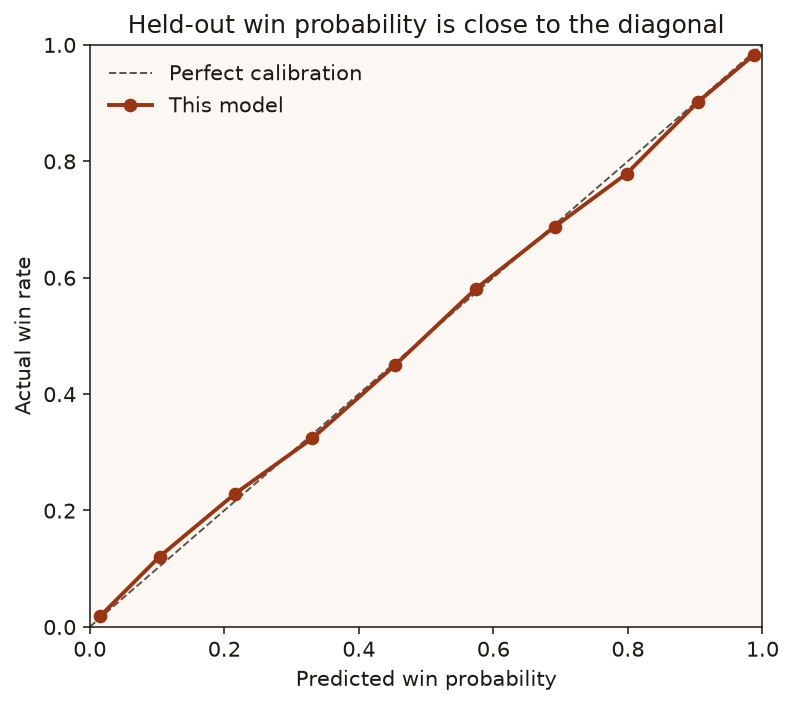

**wp_logloss_by_season.png**

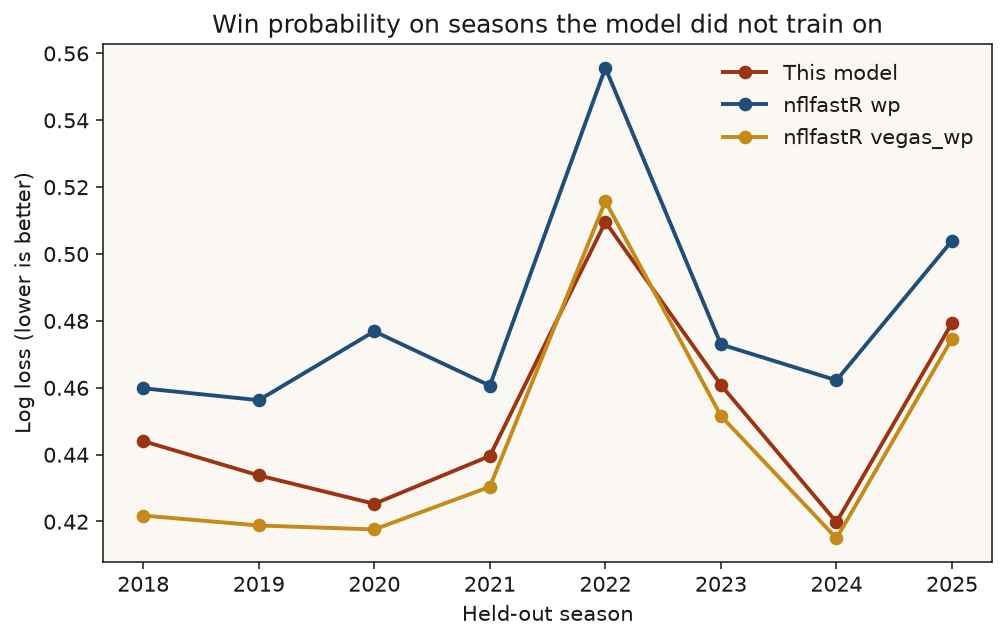

**wp_vs_nflfastr.png**

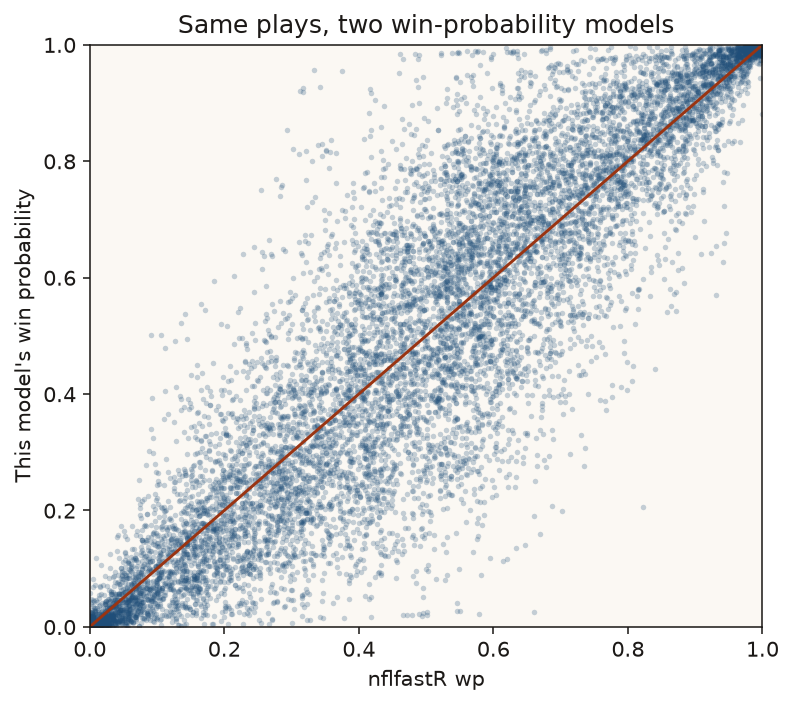

season,n,logloss_ours,logloss_raw,logloss_nflfastr,logloss_vegas,calibration_mae
i64,i64,f64,f64,f64,f64,f64
2018,36341,0.444023,0.440686,0.459808,0.42176,0.024292
2019,36835,0.433755,0.433792,0.456256,0.418787,0.014264
2020,37328,0.42527,0.425151,0.47684,0.417607,0.006157
2021,38841,0.439566,0.43945,0.4606,0.430362,0.026557
2022,38582,0.509535,0.512459,0.555596,0.515737,0.026439
2023,39249,0.460783,0.456564,0.472919,0.451545,0.034084
2024,38507,0.419799,0.419003,0.462203,0.414954,0.026119
2025,37835,0.479333,0.472465,0.50394,0.474625,0.040972


In [2]:
for name in ("wp_calibration.png", "wp_logloss_by_season.png", "wp_vs_nflfastr.png"):
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(ROOT / "figures" / name)))

metrics = pl.read_csv(ROOT / "results" / "wp_metrics_by_season.csv")
metrics.select(
    "season", "n", "logloss_ours", "logloss_raw", "logloss_nflfastr", "logloss_vegas", "calibration_mae"
)


## The chart

Green is go, gold is a field goal, navy is a punt. The right-hand panel is how much win probability the best choice has over the runner-up. On the opening kickoff the gold region is missing: a field goal that early is only a few points of win probability in this model, and going for it is a little higher. With five minutes left in a tied game, the gold band shows up. Down 3 with two minutes left, the punt disappears.


**decision_chart_opening.png**

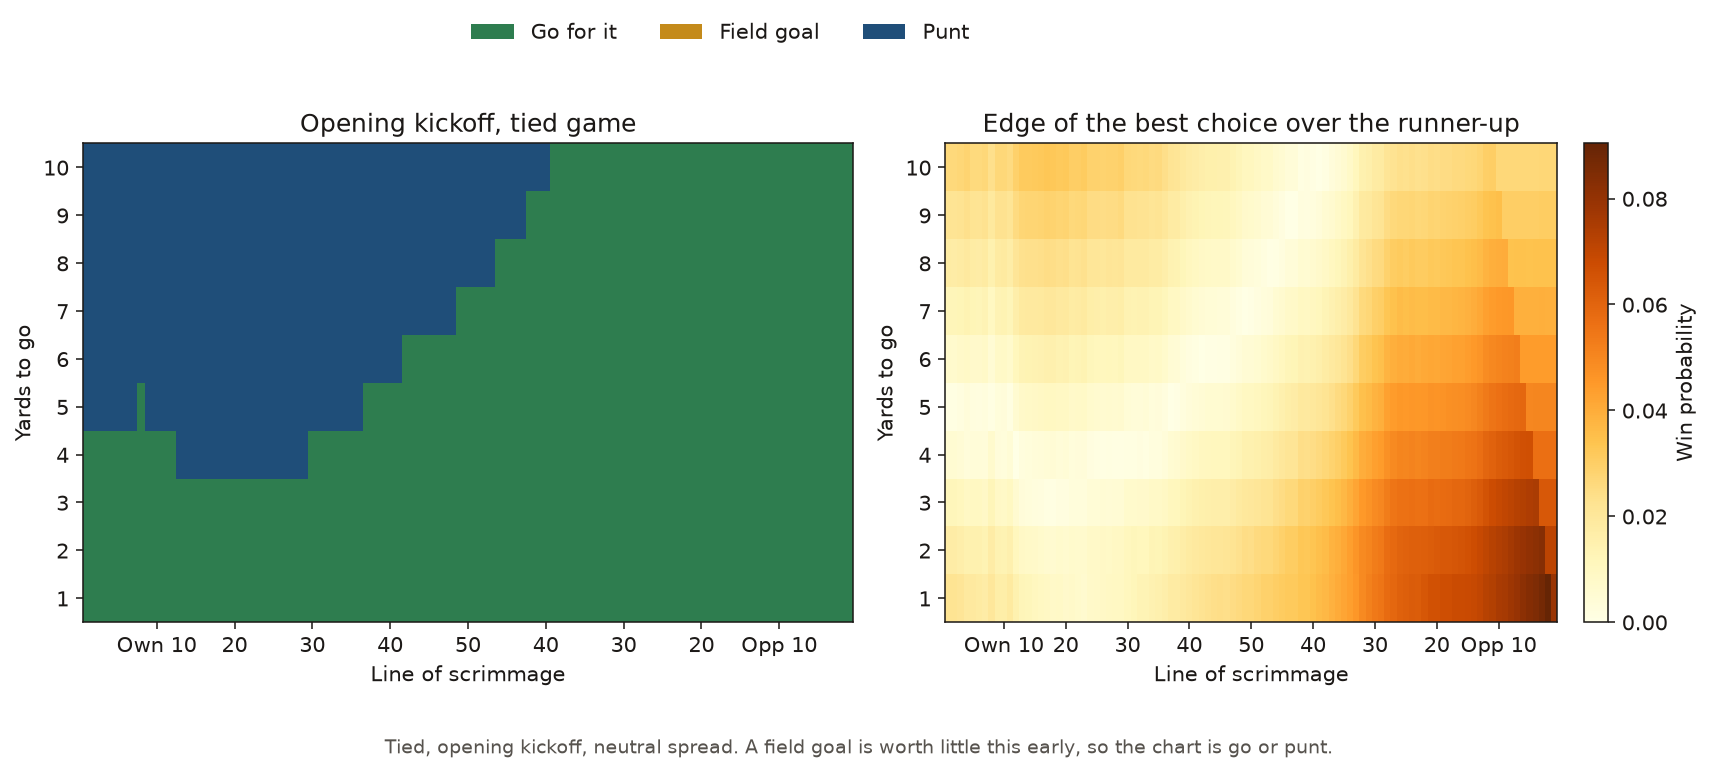

**decision_chart_q4_tied.png**

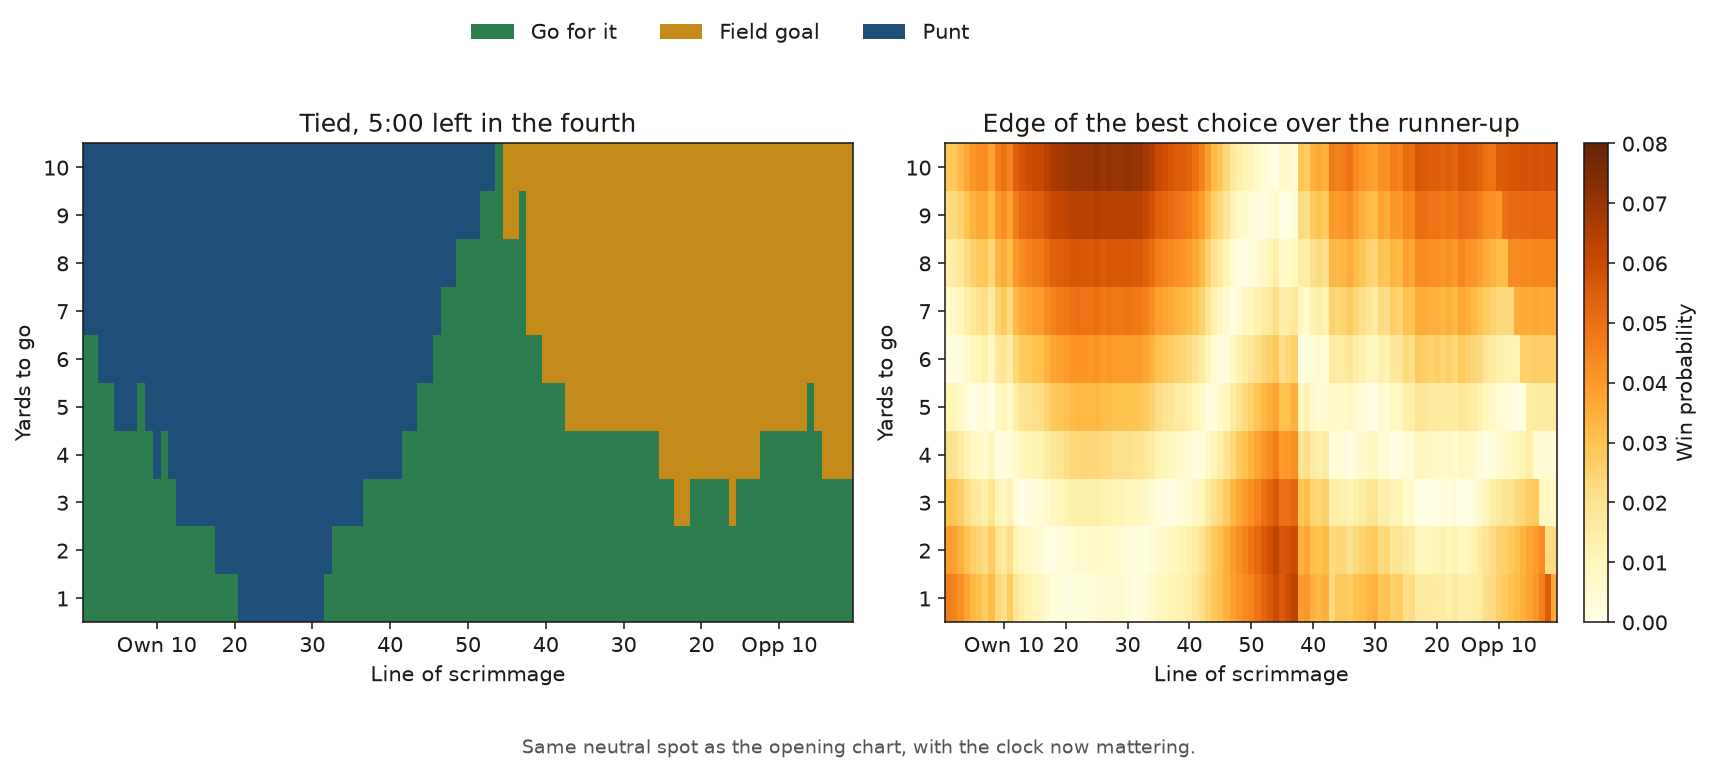

**decision_chart_q4_down3.png**

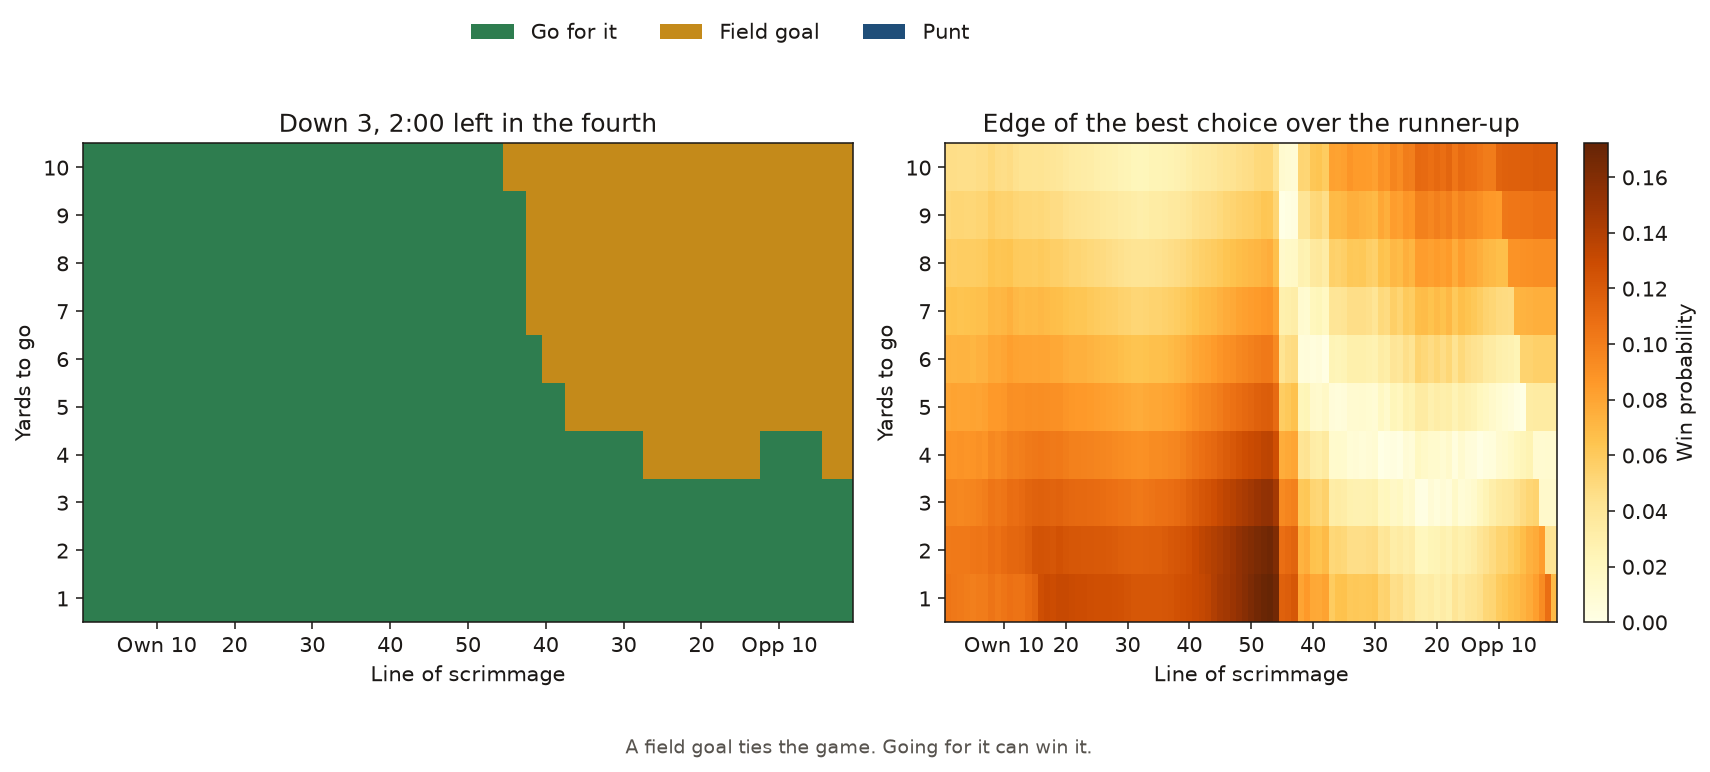

**fg_by_distance.png**

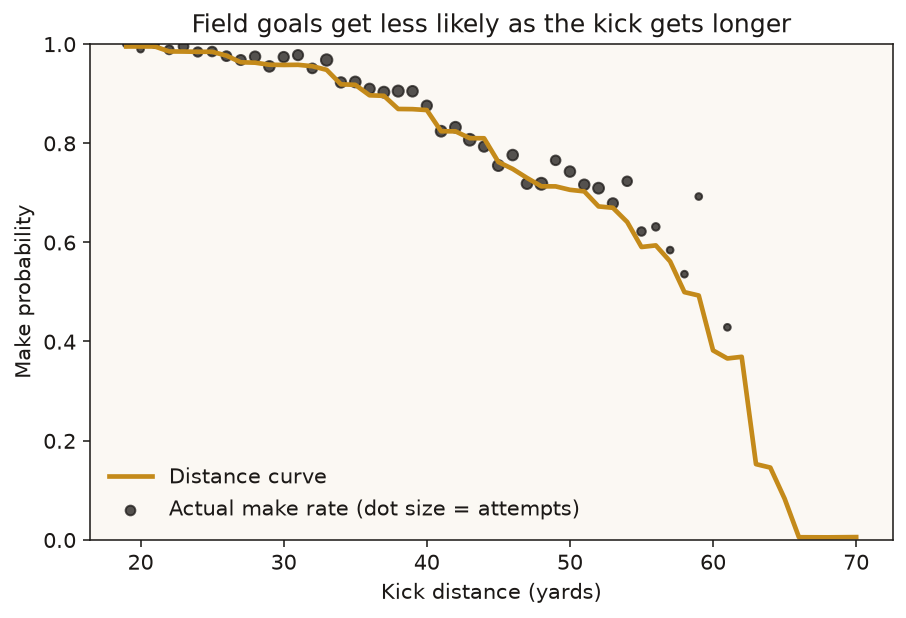

**conversion_by_ydstogo.png**

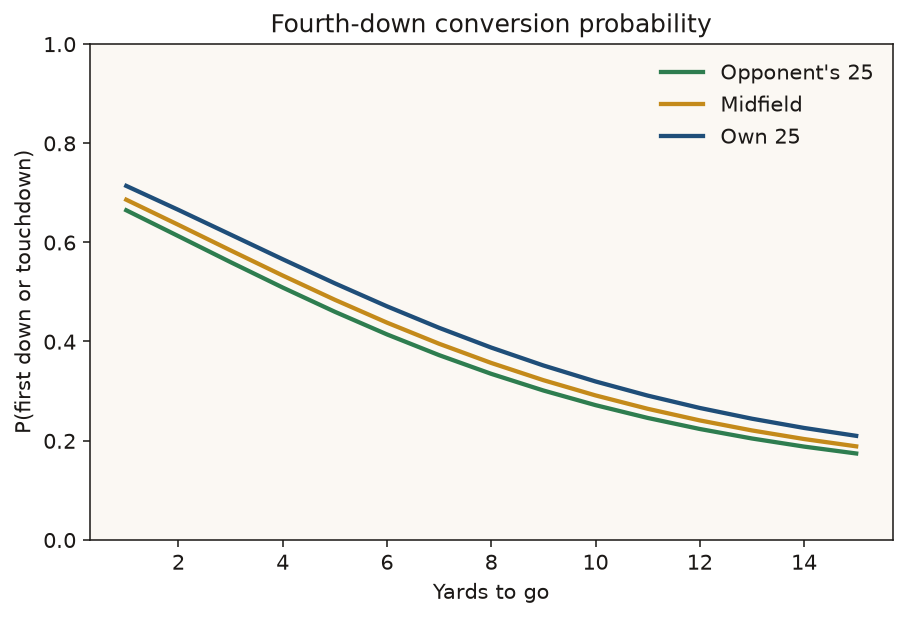

In [3]:
for name in (
    "decision_chart_opening.png",
    "decision_chart_q4_tied.png",
    "decision_chart_q4_down3.png",
    "fg_by_distance.png",
    "conversion_by_ydstogo.png",
):
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(ROOT / "figures" / name)))


## One situation, live

The bundle in `models/current.joblib` is the Sunday model: trees through 2024, probabilities scaled on 2025. Coach grades in the tables below used the stricter season holdout, so a number here and a number there are different fits.


In [4]:
bundle = joblib.load(ROOT / "models" / "current.joblib")
spots = [
    ("4th and 1, own 40, tied, opening kickoff", dict(yardline_100=60, ydstogo=1, score_diff=0, game_seconds_remaining=3600, receive_2h=1)),
    ("4th and 1, opponent 2, tied, opening kickoff", dict(yardline_100=2, ydstogo=1, score_diff=0, game_seconds_remaining=3600, receive_2h=1)),
    ("Down 3, 2:00 left, opponent 8, 4th and 3", dict(yardline_100=8, ydstogo=3, score_diff=-3, game_seconds_remaining=120, receive_2h=0)),
]
frame = make_situations([{**spot, "season": 2025, "expected_margin": 0, "is_home": 1} for _, spot in spots])
graded = choice_win_probs(frame, bundle["wp"], bundle["fg"], bundle["conv"], bundle["punt"])
for (label, _), row in zip(spots, graded.iter_rows(named=True), strict=True):
    print(
        f"{label}: {row['recommended']}  "
        f"go {row['wp_go']:.3f}  punt {row['wp_punt']:.3f}  fg {row['wp_fg']:.3f}  "
        f"edge {row['wp_edge']:.3f}"
    )


4th and 1, own 40, tied, opening kickoff: go  go 0.517  punt 0.497  fg 0.000  edge 0.020
4th and 1, opponent 2, tied, opening kickoff: go  go 0.606  punt 0.488  fg 0.515  edge 0.090
Down 3, 2:00 left, opponent 8, 4th and 3: go  go 0.464  punt 0.145  fg 0.425  edge 0.039


## Have coaches changed?

The trend query is the one in `sql/trend_by_year.sql`. DuckDB runs it here against the graded parquet so the notebook is doing the same aggregation as the pipeline. `go_rate_fourth_and_one` does not use the model. It is 4th-and-1 between the 40s.


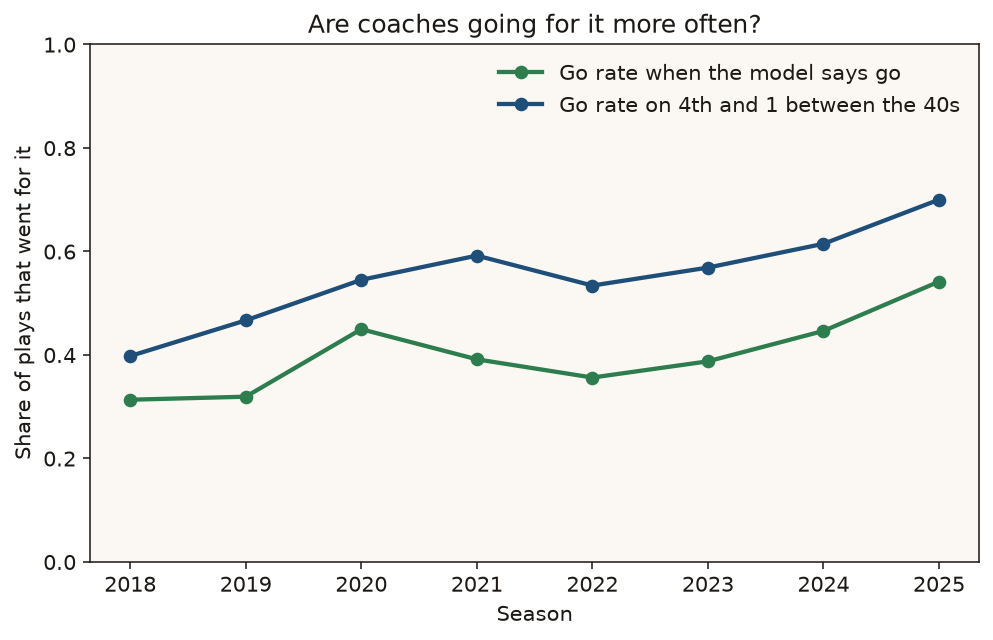

season,decisions,go_rate_all,go_rate_when_should,should_go_n,go_rate_fourth_and_one,fourth_and_one_n,wp_left_per_play
i32,i64,f64,f64,f64,f64,f64,f64
2018,2793,0.114214,0.313291,632.0,0.397727,176.0,0.009181
2019,2955,0.141794,0.319149,752.0,0.466667,165.0,0.009792
2020,2859,0.165442,0.449612,516.0,0.544974,189.0,0.006232
2021,3061,0.172819,0.391357,833.0,0.591837,196.0,0.009417
2022,3339,0.171009,0.356151,1008.0,0.533937,221.0,0.010285
2023,3572,0.180571,0.387485,831.0,0.568627,204.0,0.008203
2024,3187,0.18042,0.44625,800.0,0.614634,205.0,0.007655
2025,2983,0.197117,0.541606,685.0,0.7,200.0,0.006307


In [5]:
con = duckdb.connect()
con.execute(f"CREATE VIEW decisions AS SELECT * FROM read_parquet('{(ROOT / 'results' / 'decisions.parquet').as_posix()}')")
trend_sql = (ROOT / "sql" / "trend_by_year.sql").read_text()
trend = pl.from_pandas(con.execute(trend_sql).df())
display(Image(filename=str(ROOT / "figures" / "go_rate_trend.png")))
trend.select(
    "season",
    "decisions",
    "go_rate_all",
    "go_rate_when_should",
    "should_go_n",
    "go_rate_fourth_and_one",
    "fourth_and_one_n",
    "wp_left_per_play",
)


## Where the win probability goes

When the model says punt, coaches punt. When it says go, they usually do not. That split is the finding. The standard error on a coach treats plays as independent, so it is a little too small. Read the tails as a ranking with a sample-size warning, not as a firing list.


**Least win probability left, coaches with at least 250 decisions**

coach,teams,seasons,decisions,follow_rate,wp_left_per_play,wp_left_se,go_rate_when_should
str,str,i64,i64,f64,f64,f64,f64
"""Raheem Morris""","""ATL""",3,260,0.676923,0.00601,0.000802,0.537313
"""Dan Campbell""","""DET""",5,470,0.6,0.006353,0.000514,0.620968
"""Nick Sirianni""","""PHI""",5,506,0.614625,0.006494,0.000547,0.528926
"""Matt Eberflus""","""CHI""",3,310,0.554839,0.006617,0.000653,0.461538
"""Jonathan Gannon""","""ARI""",3,276,0.608696,0.006632,0.000783,0.464286


**Most win probability left**

coach,teams,seasons,decisions,follow_rate,wp_left_per_play,wp_left_se,go_rate_when_should
str,str,i64,i64,f64,f64,f64,f64
"""Brandon Staley""","""LAC""",3,304,0.523026,0.010037,0.000891,0.470085
"""Dennis Allen""","""NO""",3,314,0.484076,0.0103,0.00082,0.280488
"""Mike Tomlin""","""PIT""",8,867,0.538639,0.010594,0.000602,0.263598
"""Matt Patricia""","""DET""",3,252,0.503968,0.010979,0.001135,0.233333
"""Bill Belichick""","""NE""",6,556,0.482014,0.012008,0.000756,0.228395


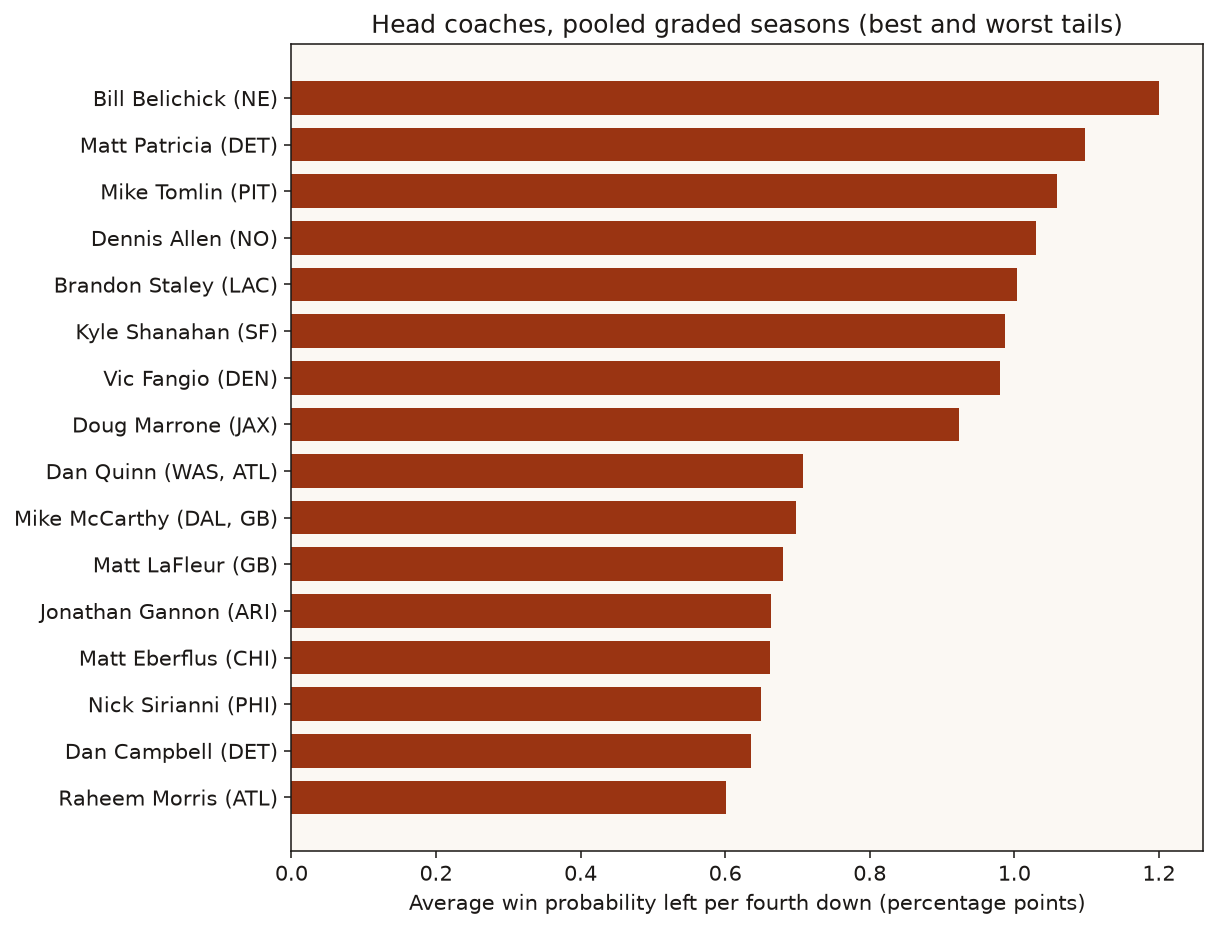

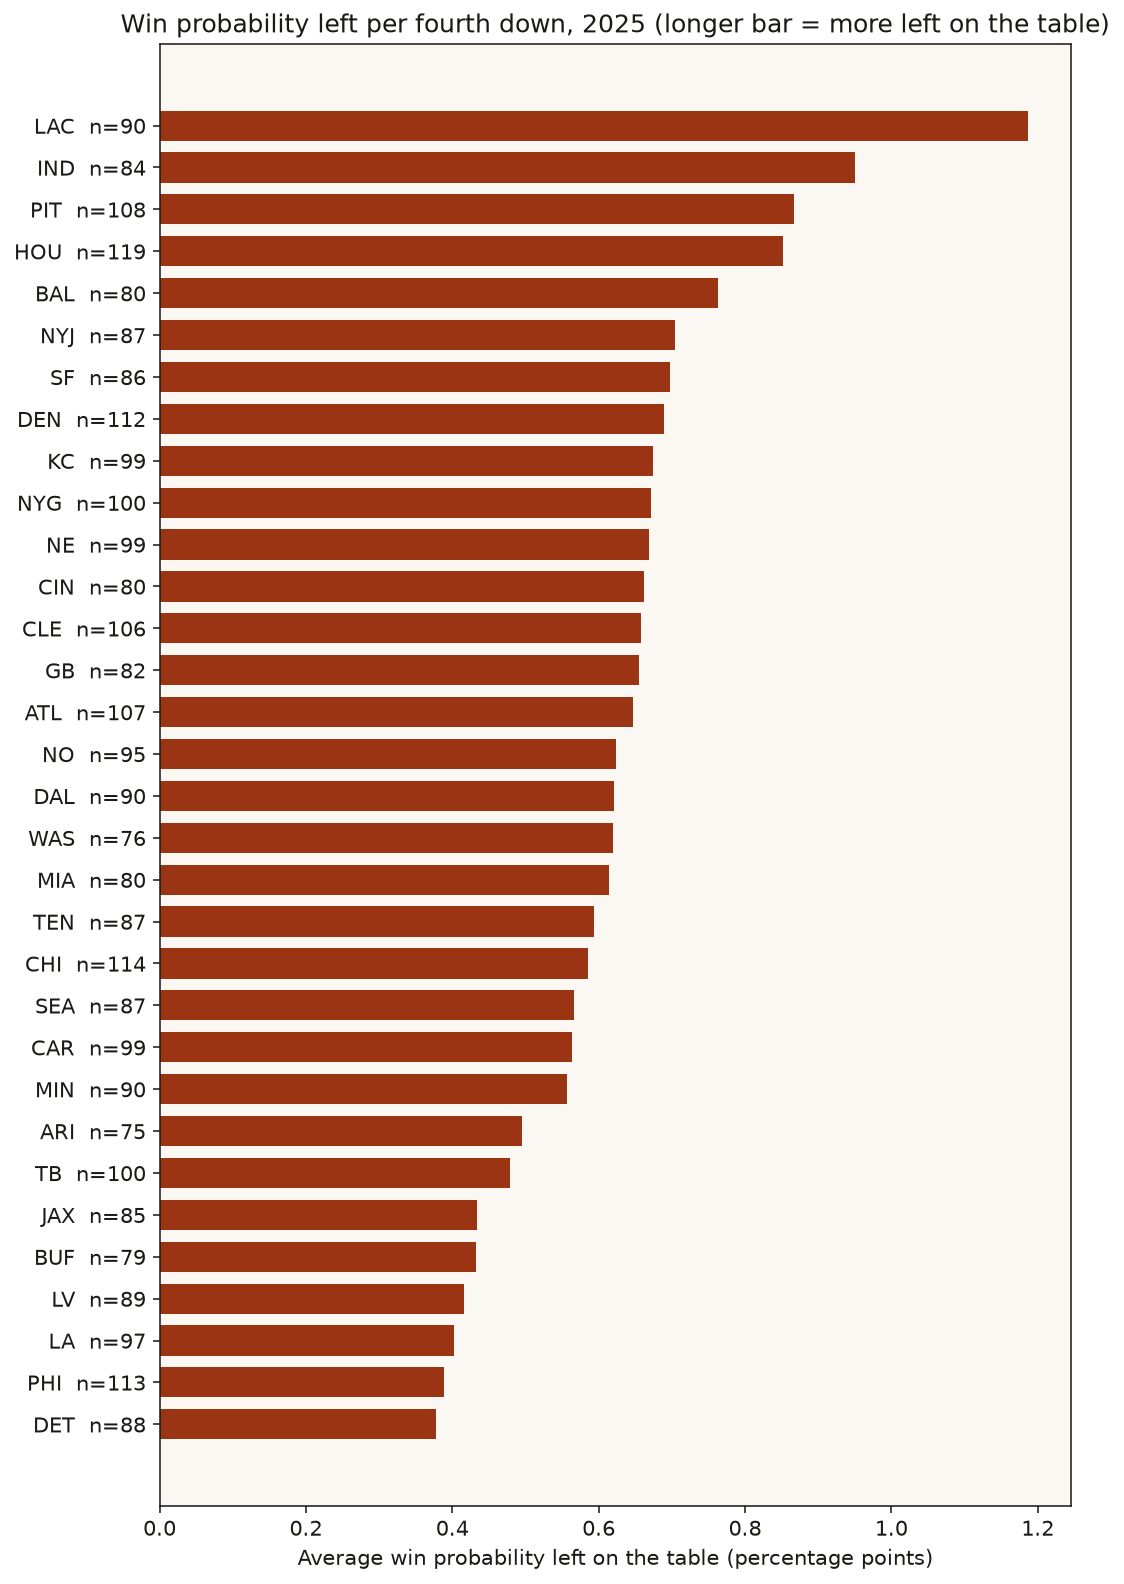

In [6]:
split = con.execute('''
SELECT recommended,
       COUNT(*) AS plays,
       AVG(CASE WHEN followed THEN 1.0 ELSE 0.0 END) AS follow_rate,
       AVG(wp_left) AS wp_left_per_play
FROM decisions
WHERE in_leaderboard
GROUP BY recommended
ORDER BY recommended
''').df()
split = pl.from_pandas(split)
split

coach_sql = (ROOT / "sql" / "coach_pooled.sql").read_text()
coaches = pl.from_pandas(con.execute(coach_sql).df())
display(Markdown("**Least win probability left, coaches with at least 250 decisions**"))
display(coaches.head(5).select("coach", "teams", "seasons", "decisions", "follow_rate", "wp_left_per_play", "wp_left_se", "go_rate_when_should"))
display(Markdown("**Most win probability left**"))
display(coaches.tail(5).select("coach", "teams", "seasons", "decisions", "follow_rate", "wp_left_per_play", "wp_left_se", "go_rate_when_should"))
display(Image(filename=str(ROOT / "figures" / "coach_wp_left_pooled.png")))
display(Image(filename=str(ROOT / "figures" / "team_wp_left_latest.png")))


## Five plays from the graded file

These are the largest out-of-sample gaps, plus one high-leverage call the coach got right. The sentence is built from the row. The play result is attached afterwards. The model did not use it.


In [7]:
examples = json.loads((ROOT / "results" / "examples.json").read_text())
for example in examples:
    display(Markdown(f"**{example['kind']}**"))
    print(example["sentence"])
    print(example["what_happened"])
    print(example["desc"])
    print()


**costliest_miss**

Shane Steichen (IND) kicked a field goal on 4th and 2 from the opponent's 4, Q4 2:42. Score at the snap: IND 27.0, HOU 29.0. The model valued go at 36.8%, punt at 8.5%, and a field goal at 19.6%, so the recommendation was to go for it. That choice left 17.3% win probability on the table.
The kick was made.
(2:42) 10-B.Grupe 22 yard field goal is GOOD, Center-46-L.Rhodes, Holder-8-R.Sanchez.



**punted_instead_of_going**

Mike Tomlin (PIT) punted on 4th and 1 from their own 44, Q4 0:44. Score at the snap: PIT 13.0, BAL 13.0. The model valued go at 52.4%, punt at 35.9%, and a field goal at 0.0%, so the recommendation was to go for it. That choice left 16.5% win probability on the table.
The next snap was at yardline_100 82 for BAL.
(:44) 6-P.Harvin punts 38 yards to BAL 18, Center-46-C.Kuntz, fair catch by 13-D.Duvernay.



**kicked_instead_of_going**

Kyle Shanahan (SF) kicked a field goal on 4th and 1 from the opponent's 15, Q4 12:43. Score at the snap: SF 24.0, LAC 26.0. The model valued go at 28.2%, punt at 11.0%, and a field goal at 16.1%, so the recommendation was to go for it. That choice left 12.1% win probability on the table.
The kick was made.
(12:43) 9-R.Gould 33 yard field goal is GOOD, Center-86-K.Nelson, Holder-5-B.Pinion.



**went_instead_of_kicking_or_punting**

Sean McDermott (BUF) went for it on 4th and 16 from the opponent's 48, Q4 1:11. Score at the snap: BUF 6.0, JAX 9.0. The model valued go at 39.7%, punt at 55.1%, and a field goal at 25.0%, so the recommendation was to punt. That choice left 15.4% win probability on the table.
They did not convert (gained 0.0 yards).
(1:11) (Shotgun) 17-J.Allen pass incomplete deep left to 14-S.Diggs.



**right_call_high_leverage**

Joe Philbin (GB) went for it on 4th and 1 from the opponent's 1, Q4 1:16. Score at the snap: GB 30.0, NYJ 35.0. The model valued go at 46.2%, punt at 4.2%, and a field goal at 15.5%, so the recommendation was to go for it. The edge over the next-best option was 30.7%.
They scored a touchdown (gained 1.0 yards).
(1:16) 12-A.Rodgers up the middle for 1 yard, TOUCHDOWN.



## What to say if someone asks about the opening chart

A made field goal on the opening drive hands the other team the ball up only three. This win-probability model prices that state near a coin flip, so going for it wins the comparison by a few points and the chart stays green. `vegas_wp` thinks those three points are worth a little more. The late-game charts are where a field goal changes the game, and the gold region is there. The README limitations section has the play counts behind that comparison.

Platt scaling, fit on the previous season, did not reduce held-out log loss (0.450 before, 0.452 after). The calibration plot is still the right check that 70% means about 70%.
